In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

### Create dummy number

Text(0.5, 1.0, '(400, 400)')

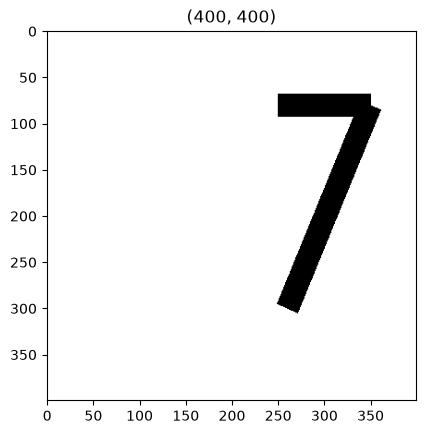

In [2]:
canvas = Image.new("L", (400, 400), 255)          # L:grayscale, (400,400): size of canvas, 255, white
d = ImageDraw.Draw(canvas)
d.line([(250, 80), (350, 80), (260, 300)], fill=0, width=25)   # a "7", top-right
raw = np.array(canvas)
plt.imshow(raw, cmap="gray"); plt.title(raw.shape)

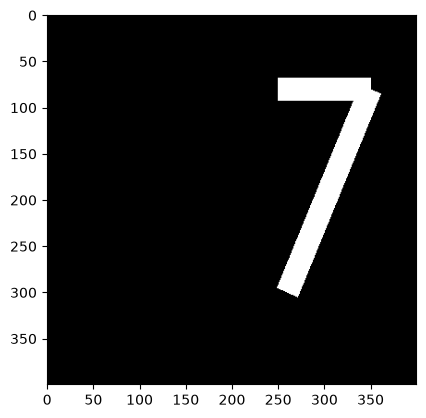

In [3]:
# Scale to [0, 1] and invert: white digit on black background, like MNIST
img = 1 - raw / 255.0            
plt.imshow(img, cmap="gray")

### Crop the image, keep only the number

In [4]:
rows = np.any(img > 0.1, axis=1)       # True/False for each of the 400 rows
r0, r1 = np.where(rows)[0][[0, -1]]    # first and last True

In [5]:
print(r0, r1)

68 305


In [6]:
columns = np.any(img > 0.1, axis=0)       # True/False for each of the 400 columns
c0, c1 = np.where(columns)[0][[0, -1]]    # first and last True

In [7]:
print(c0, c1)

249 361


(238, 113)


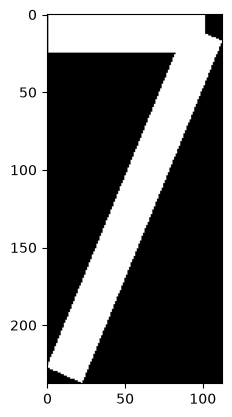

In [8]:
img = img[r0:r1 + 1, c0:c1 + 1]
print(img.shape)        # (235, 65): tall and narrow, like a 7
plt.imshow(img, cmap="gray")

### Resize the image, so it follows MNIST (must fit in 20x20 box)

longer side = max(235, 65) = 235
scale       = 20 / 235 ≈ 0.085

new height = 235 × 0.085 = 20
new width  =  65 × 0.085 ≈ 5.5 → round → 6

(20, 9)


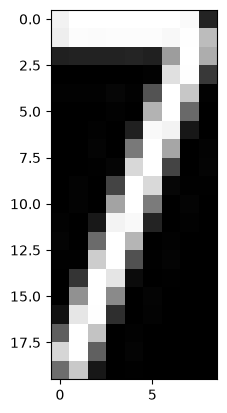

In [9]:
h, w = img.shape                              # (235, 65) after the crop
scale = 20 / max(h, w)                        # 20 / 235 ≈ 0.085
new_w = max(1, round(w * scale))              # 6   (at least 1 pixel)
new_h = max(1, round(h * scale))              # 20

small = Image.fromarray((img * 255).astype(np.uint8))   # array -> PIL image (0–255)
small = small.resize((new_w, new_h), Image.LANCZOS)     # keep the result! PIL wants (width, height)
img = np.array(small) / 255.0                           # back to an array in [0, 1]

print(img.shape)                              # (20, 6)
plt.imshow(img, cmap="gray")

### Put the digit in a 28x28 canvas

In [10]:
h, w = img.shape                     # (20, 6)
canvas28 = np.zeros((28, 28))        # black 28×28
top = (28 - h) // 2                  # 4
left = (28 - w) // 2                 # 11
canvas28[top:top + h, left:left + w] = img   # paste the digit in
img = canvas28

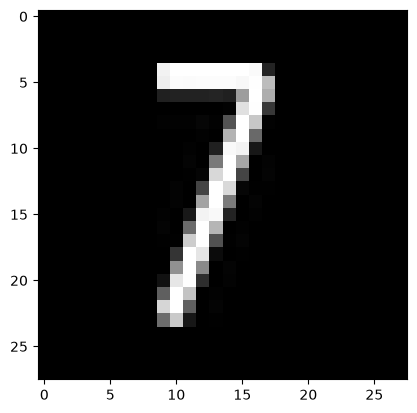

In [11]:
plt.imshow(img, cmap="gray")

In [12]:
from scipy import ndimage

cy, cx = ndimage.center_of_mass(img)          # balance point (row, column)
dy = round(13.5 - cy)                         # how far to move down
dx = round(13.5 - cx)                         # how far to move right
img = np.roll(img, (dy, dx), axis=(0, 1))

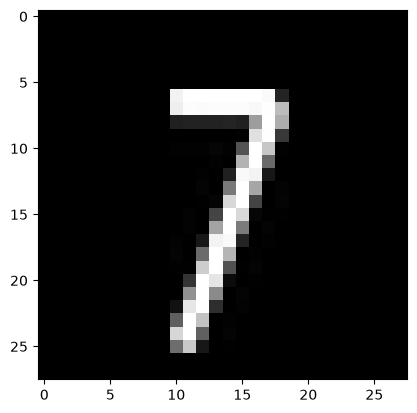

In [13]:
plt.imshow(img, cmap="gray")

### Compare with real MNIST

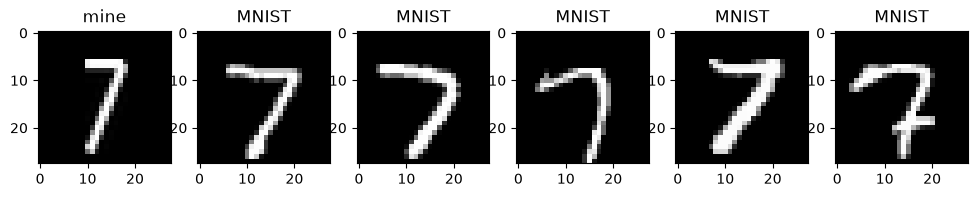

In [14]:
from src.data import get_numpy_data
_, _, (X_test, y_test) = get_numpy_data()

sevens = X_test[y_test == 7][:5]              # first 5 real 7s

fig, axes = plt.subplots(1, 6, figsize=(12, 2))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("mine")
for ax, digit in zip(axes[1:], sevens):
    ax.imshow(digit.reshape(28, 28), cmap="gray"); ax.set_title("MNIST")

In [15]:
import joblib
from src.evaluate import load_cnn, predict_cnn

x = img.reshape(1, 784).astype(np.float32)       # one flat image, float32

cnn = load_cnn("../models/cnn.pt")
print("cnn:", predict_cnn(cnn, x))               # predict_cnn calls to_cnn_input for you

for name in ["logreg", "knn", "random_forest", "svm"]:
    model = joblib.load(f"../models/{name}.joblib")
    print(f"{name}:", model.predict(x))

cnn: [7]
logreg: [7]
knn: [7]
random_forest: [7]
svm: [7]


In [16]:
from src.preprocess import to_mnist
img = to_mnist(raw)
y = img.reshape(1, 784).astype(np.float32)

In [17]:
y = img.reshape(1, 784).astype(np.float32)       # one flat image, float32

cnn = load_cnn("../models/cnn.pt")
print("cnn:", predict_cnn(cnn, y))               # predict_cnn calls to_cnn_input for you

for name in ["logreg", "knn", "random_forest", "svm"]:
    model = joblib.load(f"../models/{name}.joblib")
    print(f"{name}:", model.predict(y))

cnn: [7]
logreg: [7]
knn: [7]
random_forest: [7]
svm: [7]
